# Real Estate Housing Price Prediction (Ridge & Lasso Regression)
**Task 2** — Predict median house values on the California Housing dataset, engineer interaction features, impute missing values, handle multicollinearity, and compare **OLS**, **Ridge (L2)** and **Lasso (L1)** using **RMSE, MAE and R²**.



## 1. Imports & Configuration

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# Dataset location: URL of the starter file (a local path such as "housing.csv" also works)
DATA_PATH = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

## 2. Load the Dataset
`pd.read_csv` reads directly from the URL (no manual download needed). If loading fails, it falls back to scikit-learn's built-in California Housing dataset.

In [2]:
from sklearn.datasets import fetch_california_housing

try:
    df = pd.read_csv(DATA_PATH)
    print(f"Loaded dataset from: {DATA_PATH}")
except Exception as e:
    print(f"Could not load {DATA_PATH} ({type(e).__name__}) -> using sklearn fetch_california_housing()")
    raw = fetch_california_housing(as_frame=True).frame
    df = raw.rename(columns={
        "MedInc": "median_income", "HouseAge": "housing_median_age",
        "AveRooms": "avg_rooms", "AveBedrms": "avg_bedrooms",
        "Population": "population", "AveOccup": "avg_occupancy",
        "Latitude": "latitude", "Longitude": "longitude",
        "MedHouseVal": "median_house_value"})

df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
print(df.shape)
df.head()

Loaded dataset from: https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv
(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
TARGET = "median_house_value"
assert TARGET in df.columns, f"Target column '{TARGET}' not found. Columns: {list(df.columns)}"
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


## 3. Missing Values & Imputation
We inspect nulls first. Imputation itself is done **inside the pipeline** (median for numeric, most-frequent for categorical) so that statistics are learned from the training set only, which prevents data leakage.

In [4]:
missing = df.isna().sum()
missing = missing[missing > 0].to_frame("missing_count")
missing["missing_%"] = (missing["missing_count"] / len(df) * 100).round(2)
print("Columns with missing values:" if len(missing) else "No missing values found.")
missing

Columns with missing values:


,missing_count,missing_%
total_bedrooms,207,1.0


## 4. Exploratory Analysis & Correlation Heatmap

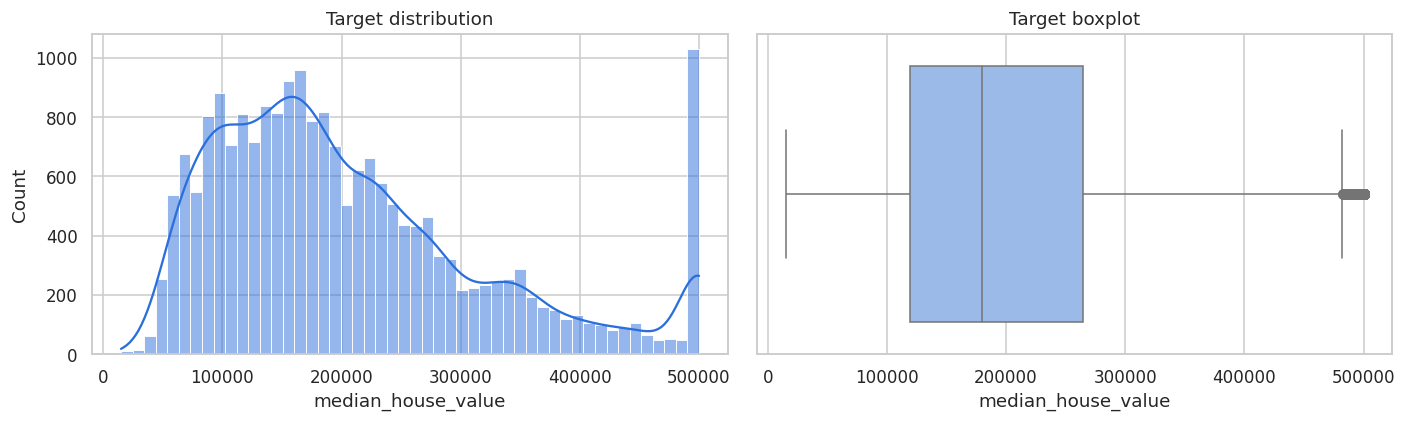

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df[TARGET], bins=50, kde=True, ax=axes[0], color="#2a6fdb")
axes[0].set_title("Target distribution")
num_cols_raw = df.select_dtypes(include=np.number).columns.tolist()
sns.boxplot(x=df[TARGET], ax=axes[1], color="#8fb8f5")
axes[1].set_title("Target boxplot")
plt.tight_layout(); plt.show()

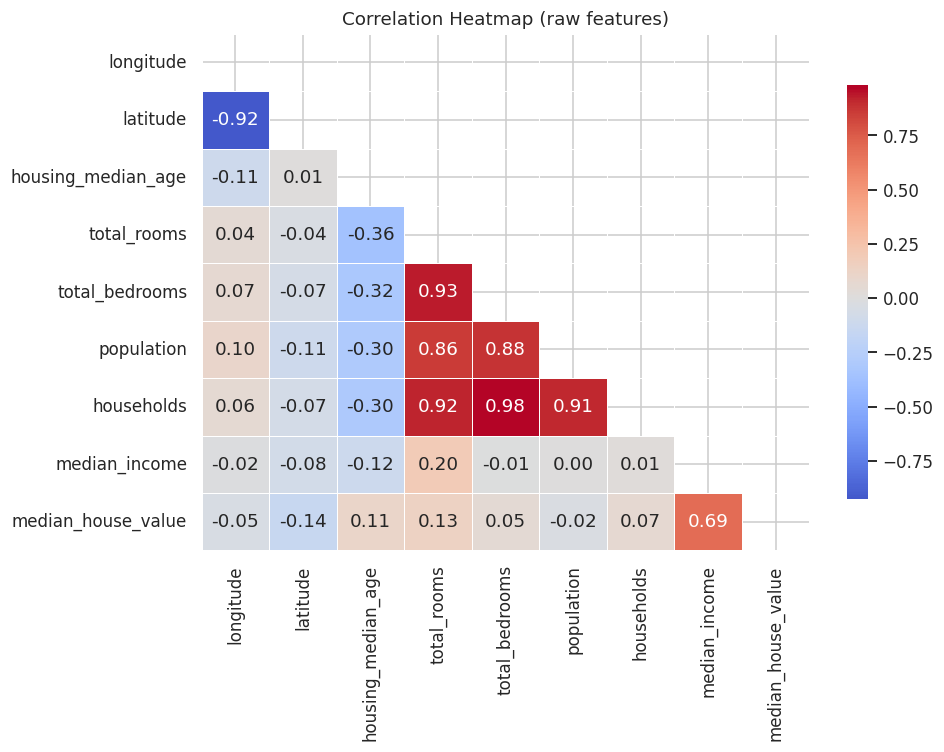

Correlation with target:


,corr
median_income,0.688
total_rooms,0.134
housing_median_age,0.106
households,0.066
total_bedrooms,0.050
population,-0.025
longitude,-0.046
latitude,-0.144


In [6]:

corr = df[num_cols_raw].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=.5, cbar_kws={"shrink": .8})
plt.title("Correlation Heatmap (raw features)")
plt.tight_layout(); plt.show()

print("Correlation with target:")
corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_frame("corr")

## 5. Feature Engineering
Adds ratio features (when the raw count columns exist) and **interaction features** (income × rooms, income × age, lat × long, etc.).

In [7]:
def engineer_features(d):
    d = d.copy()

    if {"total_rooms", "households"} <= set(d.columns):
        d["rooms_per_household"] = d["total_rooms"] / d["households"]
    if {"total_bedrooms", "total_rooms"} <= set(d.columns):
        d["bedrooms_per_room"] = d["total_bedrooms"] / d["total_rooms"]
    if {"population", "households"} <= set(d.columns):
        d["population_per_household"] = d["population"] / d["households"]


    rooms = "rooms_per_household" if "rooms_per_household" in d else "avg_rooms"
    if {"median_income", rooms} <= set(d.columns):
        d["income_x_rooms"] = d["median_income"] * d[rooms]
    if {"median_income", "housing_median_age"} <= set(d.columns):
        d["income_x_age"] = d["median_income"] * d["housing_median_age"]
    if {"latitude", "longitude"} <= set(d.columns):
        d["lat_x_long"] = d["latitude"] * d["longitude"]
    if {"median_income", "latitude"} <= set(d.columns):
        d["income_x_lat"] = d["median_income"] * d["latitude"]

    return d.replace([np.inf, -np.inf], np.nan)

df_fe = engineer_features(df)
new_feats = [c for c in df_fe.columns if c not in df.columns]
print("New engineered features:", new_feats)
df_fe[new_feats + [TARGET]].head()

New engineered features: ['rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_x_rooms', 'income_x_age', 'lat_x_long', 'income_x_lat']


,rooms_per_household,bedrooms_per_room,population_per_household,income_x_rooms,income_x_age,lat_x_long,income_x_lat,median_house_value
0,6.984127,0.146591,2.555556,58.144254,341.3332,-4630.0724,315.358576,452600.0
1,6.238137,0.155797,2.109842,51.785271,174.3294,-4627.2492,314.291004,358500.0
2,8.288136,0.129516,2.802260,60.150315,377.3848,-4626.7840,274.692590,352100.0
3,5.817352,0.184458,2.547945,32.827897,293.4412,-4627.1625,213.591335,341300.0
4,6.281853,0.172096,2.181467,24.161264,200.0024,-4627.1625,145.578670,342200.0


## 6. Train / Test Split & Preprocessing Pipeline
- Numeric: **median imputation → StandardScaler**
- Categorical: **most-frequent imputation → One-Hot encoding**

In [8]:
X = df_fe.drop(columns=[TARGET])
y = df_fe[TARGET]

num_features = X.select_dtypes(include=np.number).columns.tolist()
cat_features = X.select_dtypes(exclude=np.number).columns.tolist()
print("Numeric:", len(num_features), "| Categorical:", cat_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", StandardScaler())])
transformers = [("num", numeric_pipe, num_features)]
if cat_features:
    cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    transformers.append(("cat", cat_pipe, cat_features))
preprocessor = ColumnTransformer(transformers)
print(X_train.shape, X_test.shape)

Numeric: 15 | Categorical: ['ocean_proximity']
(16512, 16) (4128, 16)


## 7. Multicollinearity Check (VIF)
Variance Inflation Factor > 10 indicates severe multicollinearity. This is exactly the situation where OLS coefficients become unstable and regularization (Ridge/Lasso) helps.

In [9]:
Xt_num = pd.DataFrame(numeric_pipe.fit_transform(X_train[num_features]), columns=num_features)
vif = pd.DataFrame({
    "feature": num_features,
    "VIF": [variance_inflation_factor(Xt_num.values, i) for i in range(len(num_features))]
}).sort_values("VIF", ascending=False).reset_index(drop=True)
vif["severe (>10)"] = vif["VIF"] > 10
vif.round(2)

,feature,VIF,severe (>10)
0,lat_x_long,13361.22,True
1,latitude,8442.99,True
2,longitude,658.35,True
3,median_income,351.77,True
4,income_x_lat,335.74,True
5,total_bedrooms,51.02,True
6,households,47.10,True
7,total_rooms,19.65,True
8,income_x_rooms,18.01,True
9,income_x_age,9.21,False


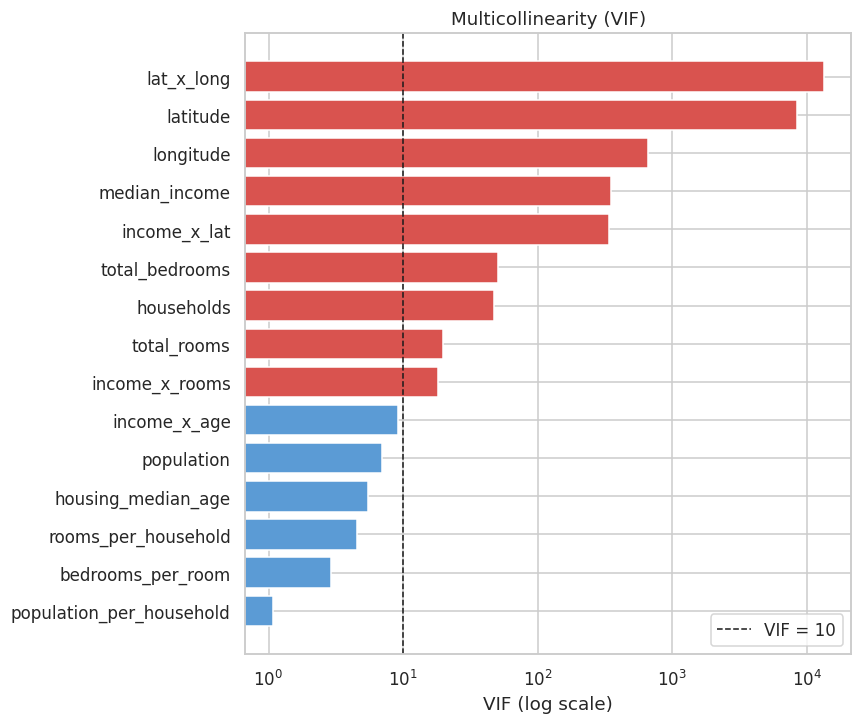

In [10]:
plt.figure(figsize=(8, 0.35 * len(vif) + 1.5))
colors = ["#d9534f" if v > 10 else "#5b9bd5" for v in vif["VIF"]]
plt.barh(vif["feature"][::-1], vif["VIF"][::-1], color=colors[::-1])
plt.axvline(10, color="k", ls="--", lw=1, label="VIF = 10")
plt.xscale("log"); plt.xlabel("VIF (log scale)"); plt.title("Multicollinearity (VIF)")
plt.legend(); plt.tight_layout(); plt.show()

## 8. Model Training
**OLS** as baseline; **Ridge** and **Lasso** tuned with `GridSearchCV` (5-fold CV) across a wide log-spaced grid of `alpha`.

In [11]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
alphas = np.logspace(-4, 3, 15)


ols = Pipeline([("prep", preprocessor), ("model", LinearRegression())])
ols.fit(X_train, y_train)

ridge_gs = GridSearchCV(
    Pipeline([("prep", preprocessor), ("model", Ridge(random_state=RANDOM_STATE))]),
    param_grid={"model__alpha": alphas}, cv=cv,
    scoring="neg_root_mean_squared_error", n_jobs=-1, return_train_score=True)
ridge_gs.fit(X_train, y_train)


lasso_gs = GridSearchCV(
    Pipeline([("prep", preprocessor), ("model", Lasso(max_iter=50000, random_state=RANDOM_STATE))]),
    param_grid={"model__alpha": alphas}, cv=cv,
    scoring="neg_root_mean_squared_error", n_jobs=-1, return_train_score=True)
lasso_gs.fit(X_train, y_train)

print("Best Ridge alpha:", ridge_gs.best_params_["model__alpha"])
print("Best Lasso alpha:", lasso_gs.best_params_["model__alpha"])

Best Ridge alpha: 0.0001
Best Lasso alpha: 0.0001


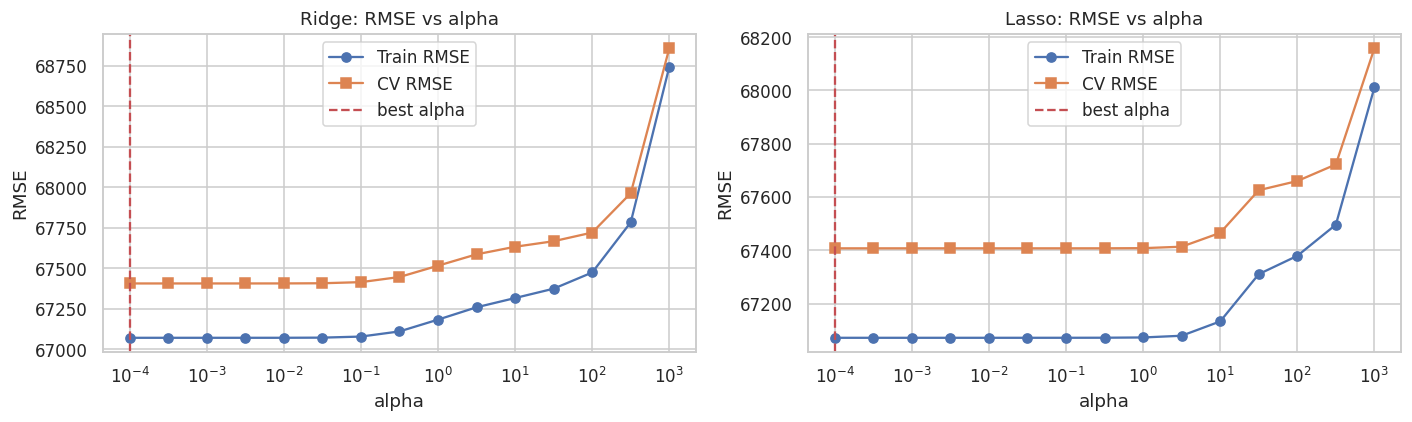

In [12]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, gs, name in zip(axes, [ridge_gs, lasso_gs], ["Ridge", "Lasso"]):
    r = pd.DataFrame(gs.cv_results_)
    a = r["param_model__alpha"].astype(float)
    ax.semilogx(a, -r["mean_train_score"], "o-", label="Train RMSE")
    ax.semilogx(a, -r["mean_test_score"], "s-", label="CV RMSE")
    ax.axvline(gs.best_params_["model__alpha"], color="r", ls="--", label="best alpha")
    ax.set_title(f"{name}: RMSE vs alpha"); ax.set_xlabel("alpha"); ax.set_ylabel("RMSE"); ax.legend()
plt.tight_layout(); plt.show()

## 9. Model Comparison (RMSE, MAE, R²)

In [13]:
models = {"OLS": ols, "Ridge (L2)": ridge_gs.best_estimator_, "Lasso (L1)": lasso_gs.best_estimator_}

def evaluate(model, Xa, ya):
    p = model.predict(Xa)
    return {"RMSE": np.sqrt(mean_squared_error(ya, p)),
            "MAE": mean_absolute_error(ya, p), "R2": r2_score(ya, p)}

rows = []
for n, m in models.items():
    tr, te = evaluate(m, X_train, y_train), evaluate(m, X_test, y_test)
    rows.append({"Model": n,
                 "Train RMSE": tr["RMSE"], "Test RMSE": te["RMSE"],
                 "Train MAE": tr["MAE"], "Test MAE": te["MAE"],
                 "Train R2": tr["R2"], "Test R2": te["R2"]})
results = pd.DataFrame(rows).set_index("Model")
results.round(4)

,Train RMSE,Test RMSE,Train MAE,Test MAE,Train R2,Test R2
Model,,,,,,
OLS,67104.8315,68546.7121,48355.0292,49153.1683,0.6631,0.6414
Ridge (L2),67104.8315,68546.7245,48355.0228,49153.1796,0.6631,0.6414
Lasso (L1),67105.0819,68549.1897,48354.1752,49156.0283,0.6631,0.6414


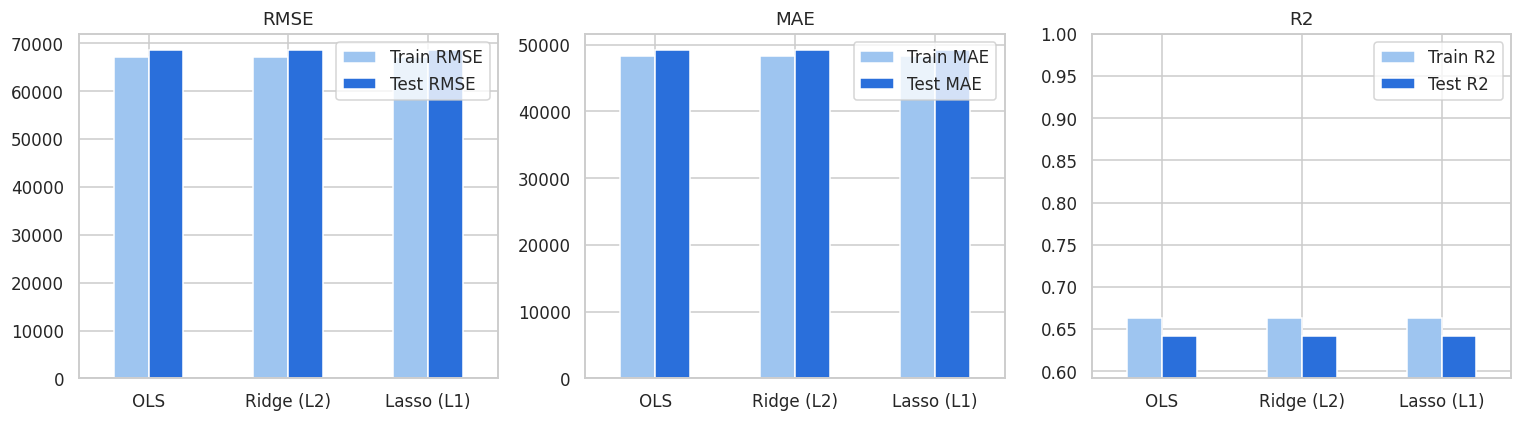

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric in zip(axes, ["RMSE", "MAE", "R2"]):
    results[[f"Train {metric}", f"Test {metric}"]].plot.bar(ax=ax, rot=0, color=["#9ec5f0", "#2a6fdb"])
    ax.set_title(metric); ax.set_xlabel("")
    if metric == "R2":
        lo = results[[f"Train {metric}", f"Test {metric}"]].min().min()
        ax.set_ylim(max(0, lo - 0.05), 1)
plt.tight_layout(); plt.show()

## 10. Coefficient Analysis (Shrinkage & Feature Selection)

In [15]:
feat_names = models["OLS"].named_steps["prep"].get_feature_names_out()
feat_names = [f.split("__", 1)[-1] for f in feat_names]

coefs = pd.DataFrame({
    "OLS":   models["OLS"].named_steps["model"].coef_,
    "Ridge": models["Ridge (L2)"].named_steps["model"].coef_,
    "Lasso": models["Lasso (L1)"].named_steps["model"].coef_,
}, index=feat_names)

n_zero = (coefs["Lasso"].abs() < 1e-8).sum()
print(f"Lasso set {n_zero} of {len(coefs)} coefficients exactly to zero.")
print("Dropped by Lasso:", coefs.index[coefs['Lasso'].abs() < 1e-8].tolist())
coefs.round(2).sort_values("OLS", key=abs, ascending=False)

Lasso set 0 of 20 coefficients exactly to zero.
Dropped by Lasso: []


,OLS,Ridge,Lasso
lat_x_long,749606.04,749478.34,725714.55
latitude,549336.46,549233.44,530049.84
longitude,-214208.92,-214182.26,-209239.12
ocean_proximity_ISLAND,115770.38,115767.44,150614.59
median_income,115345.70,115343.99,115085.34
ocean_proximity_INLAND,-61745.83,-61743.74,-26485.62
population,-45598.53,-45598.46,-45584.55
households,36627.34,36627.37,36633.61
income_x_lat,-35410.29,-35408.39,-35113.13
ocean_proximity_NEAR BAY,-22420.38,-22420.07,12496.35


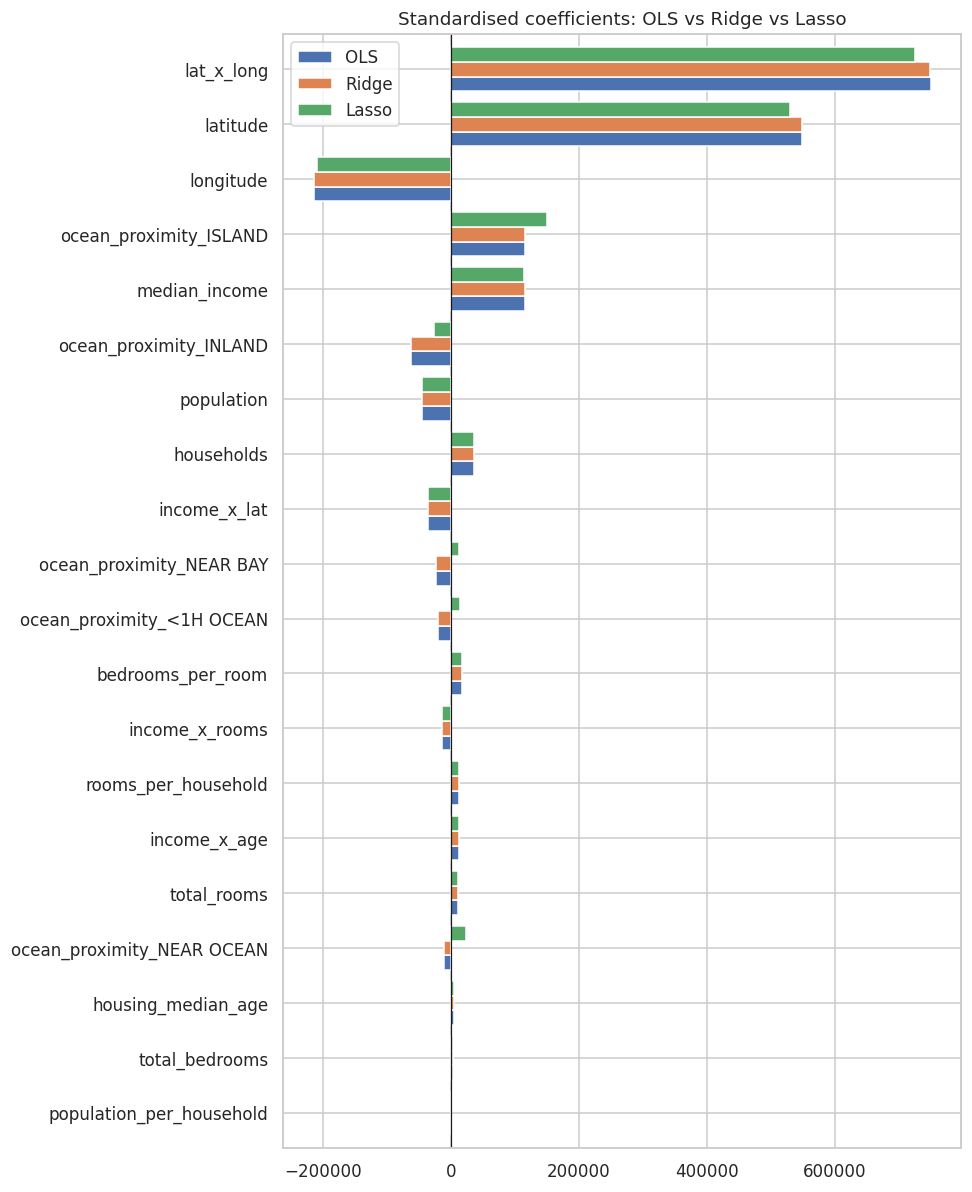

In [16]:
order = coefs["OLS"].abs().sort_values().index
ax = coefs.loc[order].plot.barh(figsize=(9, 0.45 * len(coefs) + 2), width=0.8)
ax.set_title("Standardised coefficients: OLS vs Ridge vs Lasso"); ax.axvline(0, color="k", lw=.8)
plt.tight_layout(); plt.show()

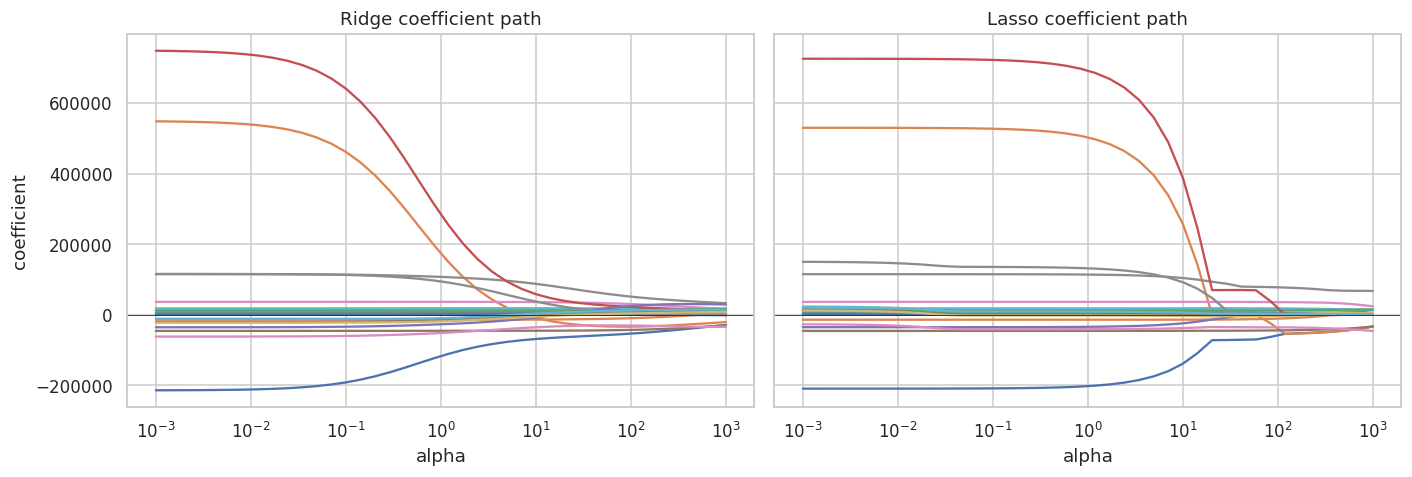

In [17]:

Xp_train = preprocessor.fit_transform(X_train)
path_alphas = np.logspace(-3, 3, 40)
ridge_path = np.array([Ridge(alpha=a).fit(Xp_train, y_train).coef_ for a in path_alphas])
lasso_path = np.array([Lasso(alpha=a, max_iter=50000).fit(Xp_train, y_train).coef_ for a in path_alphas])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, path, name in zip(axes, [ridge_path, lasso_path], ["Ridge", "Lasso"]):
    ax.semilogx(path_alphas, path)
    ax.set_title(f"{name} coefficient path"); ax.set_xlabel("alpha"); ax.axhline(0, color="k", lw=.5)
axes[0].set_ylabel("coefficient")
plt.tight_layout(); plt.show()

## 11. Predicted vs. Actual

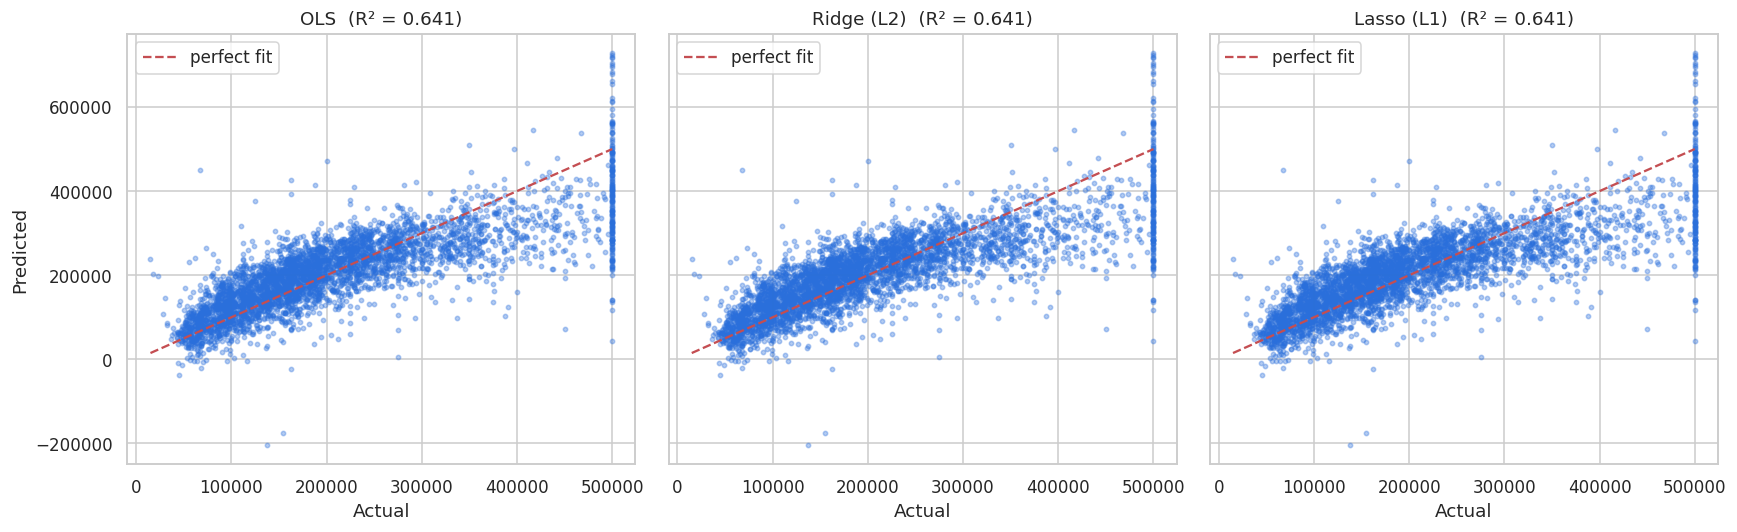

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
lims = [y_test.min(), y_test.max()]
for ax, (n, m) in zip(axes, models.items()):
    p = m.predict(X_test)
    ax.scatter(y_test, p, s=8, alpha=.35, color="#2a6fdb")
    ax.plot(lims, lims, "r--", lw=1.5, label="perfect fit")
    ax.set_title(f"{n}  (R² = {r2_score(y_test, p):.3f})")
    ax.set_xlabel("Actual"); ax.legend()
axes[0].set_ylabel("Predicted")
plt.tight_layout(); plt.show()

## 12. Residual Analysis

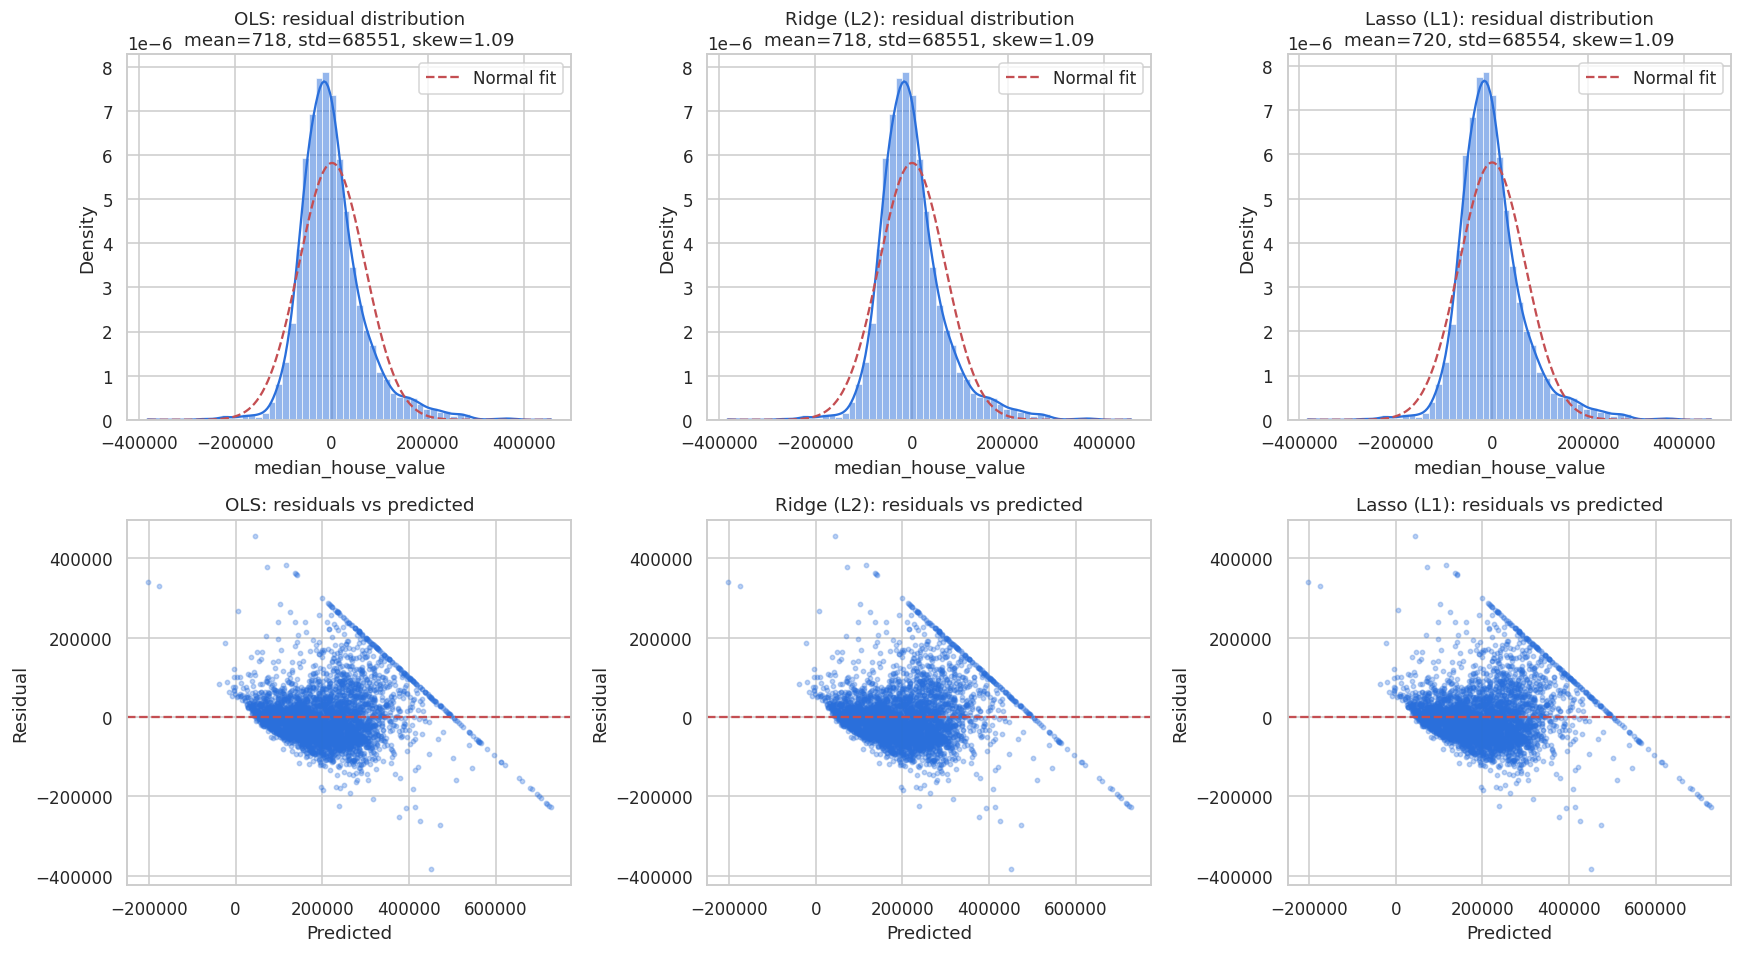

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for j, (n, m) in enumerate(models.items()):
    p = m.predict(X_test); res = y_test - p

    sns.histplot(res, bins=60, kde=True, stat="density", ax=axes[0, j], color="#2a6fdb")
    xs = np.linspace(res.min(), res.max(), 300)
    axes[0, j].plot(xs, stats.norm.pdf(xs, res.mean(), res.std()), "r--", label="Normal fit")
    axes[0, j].set_title(f"{n}: residual distribution\nmean={res.mean():.0f}, std={res.std():.0f}, skew={stats.skew(res):.2f}")
    axes[0, j].legend()

    axes[1, j].scatter(p, res, s=8, alpha=.3, color="#2a6fdb")
    axes[1, j].axhline(0, color="r", ls="--")
    axes[1, j].set_title(f"{n}: residuals vs predicted")
    axes[1, j].set_xlabel("Predicted"); axes[1, j].set_ylabel("Residual")
plt.tight_layout(); plt.show()

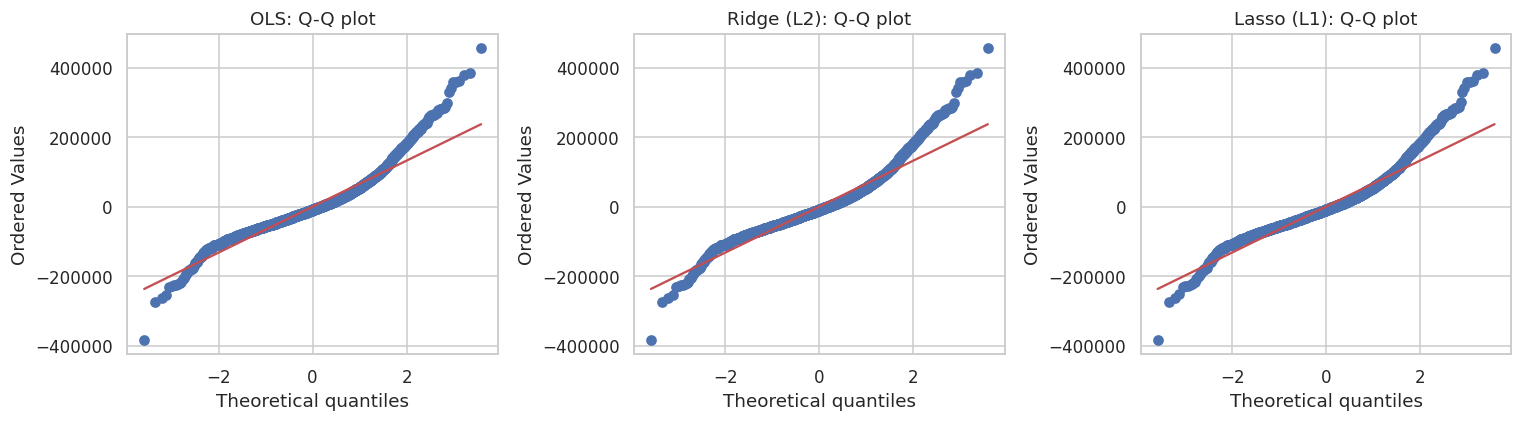

In [20]:

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (n, m) in zip(axes, models.items()):
    stats.probplot(y_test - m.predict(X_test), dist="norm", plot=ax)
    ax.set_title(f"{n}: Q-Q plot")
plt.tight_layout(); plt.show()

## 13. Summary & Conclusions

In [21]:
best = results["Test RMSE"].idxmin()
print(f"Best model by Test RMSE: {best}\n")
print(results[["Test RMSE", "Test MAE", "Test R2"]].round(4).to_string())
print(f"\nRidge best alpha = {ridge_gs.best_params_['model__alpha']:.4g}")
print(f"Lasso best alpha = {lasso_gs.best_params_['model__alpha']:.4g} "
      f"({n_zero} features eliminated)")

Best model by Test RMSE: OLS

             Test RMSE    Test MAE  Test R2
Model                                      
OLS         68546.7121  49153.1683   0.6414
Ridge (L2)  68546.7245  49153.1796   0.6414
Lasso (L1)  68549.1897  49156.0283   0.6414

Ridge best alpha = 0.0001
Lasso best alpha = 0.0001 (0 features eliminated)
